# Shadow weights in a fully connected network: 2-task multi-GEOFF

The experiment of `shadow_weights.ipynb`, moved from multi-MNIST to multi-GEOFF. Do shadow weights alone train the
hidden units, or does each unit still need gradients from the other outputs? And do shadow weights fix how the hidden
units are split between the tasks?

Fully connected, our method from `../01_distractors.ipynb` never mixes the tasks, but it splits the hidden units
unevenly between them early on and never revises the split, so it ends far above the ideal connectivity
(`../04_fully_connected.ipynb`). Shadow weights give every hidden unit a gradient from one randomly chosen output from
the start, so each task gets about as many units learning its features as it has outputs: 10 ± 2 units per task
(expected allocation 0.82). They exploit the fact that here the units should be split in proportion to the outputs, so
they are kept apart from the main line of experiments, which looks for a learner that finds the split itself.

**Shadow weights.** Each hidden unit is paired with an output drawn at random (so a task can get more or fewer than 10
units), and that connection gets a fixed shadow weight of $+1$ or $-1$, also drawn at random, used only in the backward
pass. The forward pass is unchanged and the output weights keep their true gradients. Two versions:
- *shadow weights*: a unit's gradient comes from every output through the output weights, as in backprop, except that
  the weight from its paired output counts as its shadow weight unless the real one is larger in magnitude.
- *shadow weights only*: a unit's gradient comes only from its paired output, through its shadow weight.

**Problem.** As in `../04_fully_connected.ipynb`: 2-task simple multi-GEOFF. Each task is a teacher with 21 inputs,
10 zero-threshold LTUs and 10 linear outputs, with $N(0, 1)$ noise added to each output. The inputs and every teacher
weight are random $\pm 1$ signs, so each LTU fires with probability 1/2 and each output's signal has variance about
2.5. Every 1000 steps, one task (chosen at random) has the columns of its output weights permuted.

**Networks.** 42 inputs → 20 LTU hidden units → 20 linear outputs, each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 10 hidden units per task, each reading only its own task's inputs and feeding only its own
  task's outputs.

**Learner.** Ours, as in `../04_fully_connected.ipynb`: Autostep with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and
$\tau = 10^4$, centered hidden units with a matching centered backward pass, input weights starting at
$U(-\alpha_0, \alpha_0)$, and output weights and biases starting at 0. Every run uses it, on the fully connected
network unless marked ideal connectivity. The runs without shadow weights are those of `../04_fully_connected.ipynb`.
1M steps and 30 seeds; seed $s$ gives every run the same teacher, perturbations and initial-weight draw.

**Question 1**: do shadow weights alone suffice, or does each unit still need gradients from the other outputs? Runs:
fully connected; fully connected with shadow weights only; fully connected with shadow weights; ideal connectivity.
- **H1**: shadow weights only end more than 1% above shadow weights.

**Question 2**: do shadow weights fix how the hidden units are split? The same four runs.
- **H2**: shadow weights are at most 1% above the ideal connectivity.

The hypotheses are on the excess MSE (above the noise floor) averaged over the last 10% of training, pooled over
seeds, with gaps taken per seed relative to the reference run's mean.

**Diagnostics**, fixed in advance, for the fully connected runs, as in `../04_fully_connected.ipynb`:
1. *Path purity*: the share of all input → hidden → output path weight (the product of $|w|$ along the path) that
   starts and ends in the same task. 1 means no path crosses tasks; 1/2 that the units mix the tasks evenly.
2. *Allocation*: how evenly the hidden units are split between the tasks, counting each unit for the task whose outputs
   it feeds most. 1 means 10 units each; 0 means all 20 feed one task.

The learning curves show the RMSE over outputs (its minimum, the noise, is 1), mean $\pm$ 2 SE over seeds. Everything
is recorded at step 1, then averaged over each window of 4000 steps.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd
from phd.jax_core.tasks.simple_multi_geoff import SimpleMultiGEOFFTask
from phd.jax_core.utils import stack_pytrees

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_INPUTS_PER_TASK = 21
N_TEACHER_LTUS_PER_TASK = 10
N_OUTPUTS_PER_TASK = 10
NOISE_STD = 1.0
PERTURB_PERIOD = 1000                # steps between perturbations, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10               # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records the mean of the loss, path purity and allocation

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # the loss is compared over the last 10% of training ...
LOSS_TOLERANCE = 0.01                # ... with this relative tolerance

In [3]:
LAYERS = ('w1', 'w2')
N_HIDDEN = N_TASKS * N_HIDDEN_PER_TASK
N_OUTPUTS = N_TASKS * N_OUTPUTS_PER_TASK

input_task = np.repeat(np.arange(N_TASKS), N_INPUTS_PER_TASK)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_OUTPUTS_PER_TASK)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum()} weights' for k in LAYERS))

ideal connectivity: w1 420 weights, w2 200 weights
fully connected: w1 840 weights, w2 400 weights


## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    pair: jax.Array           # each hidden unit's paired output for shadow weights ...
    sign: jax.Array           # ... and its fixed +-1 shadow weight from that output


def init_learner(key, masks):
    # Input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights and biases 0. Each hidden unit is paired with an
    # output drawn at random (several units can share one) and gets a random +-1 shadow weight.
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * INIT_STEP_SIZE * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    pair = jax.random.randint(jax.random.fold_in(key, 1), (N_HIDDEN,), 0, N_OUTPUTS)
    sign = jax.random.rademacher(jax.random.fold_in(key, 2), (N_HIDDEN,), dtype=jnp.float32)
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    return Learner(w, OPTIMIZER.init(w), jnp.full(N_HIDDEN, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25),
                   pair, sign)


def forward(w, x, learner, masks, backward='backprop'):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
    # correction leaves the value unchanged.
    correction = jnp.sum(slope * w1, axis=1)
    h = h - mean - correction + jax.lax.stop_gradient(correction)

    w2 = w['w2'] * masks['w2']
    if backward == 'backprop':
        y_hat = w2 @ jnp.append(h, 1.0)
    else:
        # Shadow weights: the outputs read h as usual, but h's gradient comes through a fixed matrix. With 'shadow
        # weights', it is the output weights, except that the weight from each unit's paired output counts as its +-1
        # shadow weight unless the real one is larger in magnitude. With 'shadow weights only', it holds just the
        # shadow weights, so each unit hears only from its paired output. The last two terms cancel in value, and the
        # output weights keep their true gradient.
        units = jnp.arange(N_HIDDEN)
        if backward == 'shadow weights':
            real = w2[learner.pair, units]
            feedback = w2[:, :-1].at[learner.pair, units].set(jnp.where(jnp.abs(real) > 1.0, real, learner.sign))
        else:
            feedback = jnp.zeros_like(w2[:, :-1]).at[learner.pair, units].set(learner.sign)
        feedback = jax.lax.stop_gradient(feedback)                                      # (output, unit)
        y_hat = w2 @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, y, masks, backward='backprop'):
    # One online Autostep update, with the `backward` pass of forward(). Returns the new learner and the squared error
    # summed over outputs.
    def loss_fn(w):
        y_hat, aux = forward(w, x, learner, masks, backward)
        return 0.5 * jnp.sum((y_hat - y) ** 2), aux

    (loss, (source_values, mean, slope)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope), 2.0 * loss

## Training

In [5]:
WINDOW = NUM_STEPS // N_WINDOWS


def diagnostics(w):
    # Path purity: the share of all input -> hidden -> output path weight (the product of |w| along the path) that
    # starts and ends in the same task. Allocation: how evenly the hidden units are split between the tasks, counting
    # each unit for the task whose outputs it feeds most; 1 when every task has the same number, 0 when all units feed
    # one task. Biases are left out.
    # Inputs and outputs are laid out task by task, so (unit, task) sums are reshapes.
    reads = jnp.abs(w['w1'][:, :-1]).reshape(N_HIDDEN, N_TASKS, -1).sum(2)       # |w| into each unit from each task
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, -1, N_HIDDEN).sum(1).T     # |w| out of each unit to each task
    units = (feeds.argmax(1)[:, None] == np.arange(N_TASKS)).sum(0)              # hidden units per task
    return {'path purity': (reads * feeds).sum() / (reads.sum(1) * feeds.sum(1)).sum(),
            'allocation': (1 - units.max() / N_HIDDEN) / (1 - 1 / N_TASKS)}


def train(key, task, masks, backward='backprop'):
    # Step 1 on its own, then NUM_STEPS online steps in windows, with the `backward` pass of forward(). Returns the
    # per-output MSE, and the path purity and allocation: at step 1, then averaged over every window.
    def one_step(carry, _):
        learner, task, total = carry
        task, (x, y) = task.generate_batch(1)
        learner, sq_err = learner_step(learner, x[0], y[0], masks, backward)
        total = jax.tree.map(jnp.add, total, diagnostics(learner.w))
        return (learner, task, total), sq_err

    def window(carry, _):
        learner, task = carry
        zeros = jax.tree.map(jnp.zeros_like, diagnostics(learner.w))
        (learner, task, total), sq_err = jax.lax.scan(one_step, (learner, task, zeros), length=WINDOW)
        return (learner, task), (sq_err.mean() / N_OUTPUTS, jax.tree.map(lambda t: t / WINDOW, total))

    task, (x, y) = task.generate_batch(1)
    learner, sq_err = learner_step(init_learner(key, masks), x[0], y[0], masks, backward)
    _, (mse, values) = jax.lax.scan(window, (learner, task), length=N_WINDOWS)
    first = (sq_err / N_OUTPUTS, diagnostics(learner.w))
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, (mse, values))


def seeds():
    # Init keys and teachers. Seed s uses teacher s (and its perturbations) and init key s for every run, so runs are
    # paired.
    tasks = stack_pytrees([
        SimpleMultiGEOFFTask(N_TASKS, perturb_period=PERTURB_PERIOD, n_features_per_task=N_INPUTS_PER_TASK,
                             n_hidden_per_task=N_TEACHER_LTUS_PER_TASK, n_outputs_per_task=N_OUTPUTS_PER_TASK,
                             noise_std=NOISE_STD, seed=s)
        for s in range(N_SEEDS)])
    return jax.random.split(jax.random.PRNGKey(0), N_SEEDS), tasks


def run(network, backward='backprop'):
    # Trains ours on `network` (a key of MASKS) on every seed, vmapped into one scan, with the `backward` pass of
    # forward(). Returns the excess MSE, the RMSE, the path purity and the allocation, each (seed, step 1 + window).
    keys, tasks = seeds()
    mse, values = jax.jit(jax.vmap(lambda key, task: train(key, task, MASKS[network], backward)))(keys, tasks)
    mse = np.asarray(mse)
    return {'excess_mse': mse - NOISE_STD ** 2, 'rmse': np.sqrt(mse), **jax.tree.map(np.asarray, values)}

## Results

The four runs serve both questions; H1 and H2 as stated at the top.

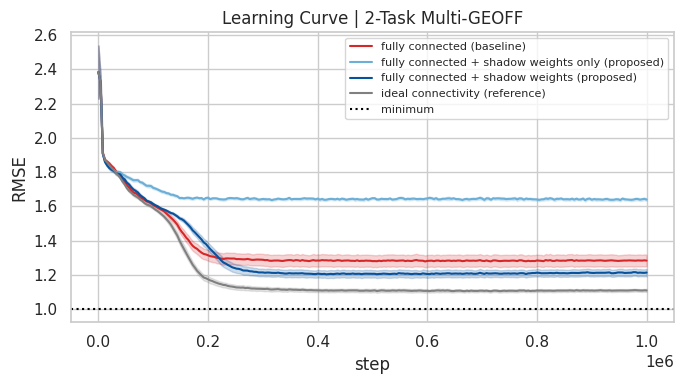

fully connected (baseline)                         excess MSE 0.6555
fully connected + shadow weights only (proposed)   excess MSE 1.6912
fully connected + shadow weights (proposed)        excess MSE 0.4728
ideal connectivity (reference)                     excess MSE 0.2295
H1, shadow weights only vs shadow weights: +257.7% (± 10.3%): held
H2, shadow weights vs ideal connectivity: +106.0% (± 24.7%): failed


In [6]:
BASELINE = 'fully connected (baseline)'
SHADOW_ONLY = 'fully connected + shadow weights only (proposed)'
SHADOW = 'fully connected + shadow weights (proposed)'
IDEAL = 'ideal connectivity (reference)'
runs = {BASELINE: run('fully connected'),
        SHADOW_ONLY: run('fully connected', 'shadow weights only'),
        SHADOW: run('fully connected', 'shadow weights'),
        IDEAL: run('ideal connectivity')}
COLORS = {BASELINE: 'tab:red', SHADOW_ONLY: '#6baed6', SHADOW: '#08519c', IDEAL: 'gray'}

STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window
plt.figure(figsize=(7, 4))
for label, res in runs.items():
    mean = res['rmse'].mean(0)
    sem = res['rmse'].std(0) / np.sqrt(N_SEEDS)
    plt.plot(STEPS, mean, color=COLORS[label], lw=1.5, label=label)
    plt.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=COLORS[label], alpha=0.2)
plt.axhline(NOISE_STD, color='black', lw=1.5, ls=':', label='minimum')
plt.xlabel('step')
plt.ylabel('RMSE')
plt.title('Learning Curve | 2-Task Multi-GEOFF')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Each seed's excess MSE over the last FINAL_FRACTION of training.
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
loss = {label: res['excess_mse'][:, final].mean(1) for label, res in runs.items()}
for label, l in loss.items():
    print(f'{label:<50} excess MSE {l.mean():.4f}')


def gap(label, reference):
    # The per-seed gap of `label` to `reference` on the same seed, relative to the reference's mean: its mean and 2 SE.
    g = (loss[label] - loss[reference]) / loss[reference].mean()
    return g.mean(), 2 * g.std() / np.sqrt(N_SEEDS)


held = lambda ok: 'held' if ok else 'failed'
h1, h1_se = gap(SHADOW_ONLY, SHADOW)
h2, h2_se = gap(SHADOW, IDEAL)
print(f'H1, shadow weights only vs shadow weights: {h1:+.1%} (± {h1_se:.1%}): {held(h1 > LOSS_TOLERANCE)}')
print(f'H2, shadow weights vs ideal connectivity: {h2:+.1%} (± {h2_se:.1%}): {held(h2 <= LOSS_TOLERANCE)}')

### Diagnostics: mixing and unit allocation

Path purity and allocation over training for the fully connected runs (mean $\pm$ 2 SE over seeds).

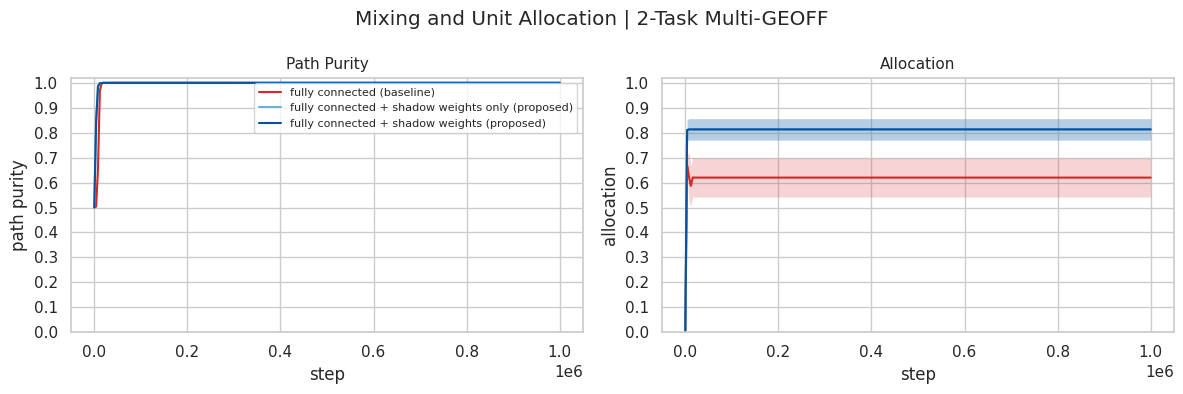

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, quantity in zip(axes, ('path purity', 'allocation')):
    for label in (BASELINE, SHADOW_ONLY, SHADOW):
        v = runs[label][quantity]                                                                   # (seed, step)
        mean, sem = v.mean(0), v.std(0) / np.sqrt(N_SEEDS)
        ax.plot(STEPS, mean, color=COLORS[label], lw=1.5, label=label)
        ax.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=COLORS[label], alpha=0.2, lw=0)
    ax.set_ylim(0, 1.02)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
    ax.set_xlabel('step')
    ax.set_ylabel(quantity)
    ax.set_title(quantity.title(), fontsize=11)
axes[0].legend(fontsize=8)
fig.suptitle('Mixing and Unit Allocation | 2-Task Multi-GEOFF')
fig.tight_layout()
plt.show()

## Results

- **H1 held.** Shadow weights only end 258% (± 10%, 2 SE over paired seeds) above shadow weights (excess MSE 1.691
  against 0.473), and far above the plain fully connected network (0.656): each unit still needs gradients from the
  other outputs.
- **H2 failed.** Shadow weights end 106% (± 25%) above the ideal connectivity (0.230), though below the plain fully
  connected network.
- **Diagnostics.** Path purity reaches 1 within about 20k steps in every run. With either version of shadow weights
  (the two lines overlap), allocation is 0.82 from the first window on, the split that the random pairing gives,
  against 0.62 without them.
- On multi-MNIST, shadow weights came within 1 point of the ideal connectivity with the same allocation; here the
  uneven split still costs a lot. A likely reason, not tested: each multi-GEOFF teacher has exactly 10 LTUs, so a task
  with fewer than 10 units cannot fit its targets, while an MNIST task loses little accuracy beyond about 5 units.